### Wine Quality - 추가 분석 : 교차검증 + Pipeline (공통 모델링 시리즈 ①)
### 학습 내용
 * 기본 분석([01_06_WindQT_DataAnalysis](https://ldjwj.github.io/dataAnalysis/01_06_WindQT_DataAnalysis.html))의 **train_test_split 1회 평가**가 얼마나 흔들리는지 확인하고 **교차검증(StratifiedKFold)**으로 믿을 수 있게 평가하기
 * **Pipeline**(StandardScaler + 모델)으로 전처리와 모델을 한 번에 묶고, 여러 모델 비교와 **GridSearchCV** 튜닝하기
 * 품질을 3등급으로 묶은 분류와 **변수 중요도**(feature_importances_, permutation importance) 해석하기

### 내용
 * 0. 기본 분석 돌아보기 - 무엇을 보완할까?
 * 1. 데이터 준비 (Id 컬럼 제외)
 * 2. train_test_split 1회 vs StratifiedKFold 교차검증
 * 3. Pipeline - 스케일링과 모델을 하나로
 * 4. 여러 모델 비교 (전체 변수)
 * 5. GridSearchCV로 간단히 튜닝하기
 * 6. 품질을 3등급(낮음/보통/높음)으로 묶어 분류하기
 * 7. 변수 중요도
 * 8. 정리

### 0. 기본 분석 돌아보기 - 무엇을 보완할까?
 * 기본 분석은 11개 화학 변수 중 **4개만**(`fixed acidity`, `volatile acidity`, `citric acid`, `residual sugar`) 사용했다.
   * 기본 설정 테스트 정확도 : KNN 0.513, DecisionTree(depth=3) 0.516, RandomForest(depth=3) 0.534
   * RandomForest를 max_depth=7, n_estimators=500으로 바꿔 **최종 테스트 정확도 0.612**(학습 0.778)
 * 한계
   * 평가는 `train_test_split(random_state=0)` **한 번의 분할**로만 했다. 다른 분할이면 점수가 달라질 수 있다.
   * max_depth와 트리 개수를 **테스트 데이터 점수를 보면서** 골랐다. → 테스트 점수가 실제보다 좋게 나올 수 있다(테스트 데이터에 맞춘 셈).
   * 나머지 7개 변수(알코올, 황산염 등)는 사용하지 않았다.

### 필수 라이브러리 불러오기

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.inspection import permutation_importance

# 한글 폰트 설정
# - koreanize-matplotlib이 설치되어 있으면 OS와 상관없이 나눔고딕을 사용 (pip install koreanize-matplotlib)
# - 없으면 OS에 맞는 기본 한글 폰트를 사용
try:
    import koreanize_matplotlib
except ImportError:
    import platform
    plt.rcParams['font.family'] = {'Windows': 'Malgun Gothic',
                                   'Darwin': 'AppleGothic'}.get(platform.system(), 'NanumGothic')
plt.rcParams['axes.unicode_minus'] = False

sns.set_theme(style='whitegrid', font=plt.rcParams['font.family'])

### 1. 데이터 준비 (Id 컬럼 제외)
 * `Id`는 행 번호일 뿐 와인의 성질이 아니다. 입력 변수에 넣으면 **의미 없는 패턴**(데이터가 저장된 순서)을 외울 수 있으므로 제외한다.

In [2]:
dat = pd.read_csv("./data/WineQT/WineQT.csv")
print(dat.shape)

features = [c for c in dat.columns if c not in ['quality', 'Id']]
X = dat[features]
y = dat['quality']
print('입력 변수 개수 :', len(features))
y.value_counts().sort_index()

(1143, 13)
입력 변수 개수 : 11


quality
3      6
4     33
5    483
6    462
7    143
8     16
Name: count, dtype: int64

In [3]:
# Id를 제외하고 같은 값을 가진 행
print('Id 제외 중복 행 :', dat[features + ['quality']].duplicated().sum())

Id 제외 중복 행 : 125


* 한줄 확인 : 1,143행, 입력 변수 11개(Id, quality 제외). 품질은 **5(483개), 6(462개)**에 85%가 몰려 있고 3(6개), 8(16개)은 매우 적다.
  * Id를 빼면 모든 값이 같은 행이 125개 있다. 같은 와인이 여러 번 기록되었을 수 있지만, 이번에는 기본 분석과 같이 **그대로 사용**한다.
  * 품질별 개수 차이가 크므로, 나눌 때마다 품질 비율이 유지되도록 **층화(stratify)** 분할을 사용한다.

### 2. train_test_split 1회 vs StratifiedKFold 교차검증
 * 같은 모델(RandomForest, 전체 11개 변수)을 **random_state만 바꿔 30번** 나누어 테스트 정확도가 얼마나 달라지는지 본다.

In [4]:
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=2)

split_scores = []
for seed in range(30):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=seed, stratify=y)
    rf.fit(X_tr, y_tr)
    split_scores.append(rf.score(X_te, y_te))
split_scores = np.array(split_scores)

print('split 30회 테스트 정확도 - 최소 %.3f / 최대 %.3f / 평균 %.3f / 표준편차 %.3f'
      % (split_scores.min(), split_scores.max(), split_scores.mean(), split_scores.std()))

split 30회 테스트 정확도 - 최소 0.598 / 최대 0.729 / 평균 0.658 / 표준편차 0.031


In [5]:
# 5겹 층화 교차검증을 seed를 바꿔 10번 반복 → 교차검증 '평균'이 얼마나 흔들리는지
cv_means = []
for seed in range(10):
    skf_s = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    cv_means.append(cross_val_score(rf, X, y, cv=skf_s).mean())
cv_means = np.array(cv_means)

print('5겹 교차검증 평균 10회 - 최소 %.3f / 최대 %.3f / 평균 %.3f / 표준편차 %.3f'
      % (cv_means.min(), cv_means.max(), cv_means.mean(), cv_means.std()))

5겹 교차검증 평균 10회 - 최소 0.661 / 최대 0.675 / 평균 0.668 / 표준편차 0.004


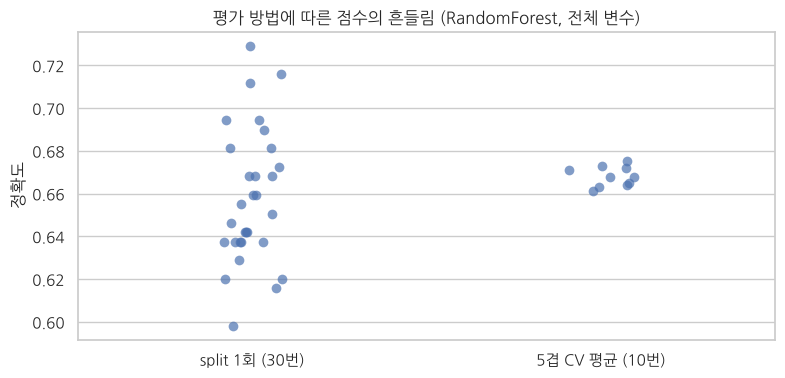

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.stripplot(x=['split 1회 (30번)'] * len(split_scores) + ['5겹 CV 평균 (10번)'] * len(cv_means),
              y=np.r_[split_scores, cv_means], size=7, alpha=0.7, ax=ax)
ax.set_ylabel('정확도')
ax.set_title('평가 방법에 따른 점수의 흔들림 (RandomForest, 전체 변수)')
plt.show()

* 한줄 확인 : 같은 모델인데도 **분할만 바꾸면 테스트 정확도가 0.598 ~ 0.729**(약 13%p 차이, 표준편차 0.031)로 흔들린다.
  * 5겹 교차검증 평균은 seed를 바꿔도 **0.661 ~ 0.675**(표준편차 0.004)로 훨씬 안정적이다. 그래프에서도 오른쪽 점들이 촘촘히 모여 있다.
  * 점수 하나만 보고 "모델 A가 B보다 좋다"고 말하기 어렵다. 앞으로는 **5겹 층화 교차검증의 평균(± 표준편차)**으로 비교한다.

#### 기본 분석과 같은 조건(4개 변수)을 교차검증으로 다시 평가하면?

In [7]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
base_sel = ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar']
rf_base = RandomForestClassifier(max_depth=7, n_estimators=500, random_state=42, n_jobs=2)

s4 = cross_val_score(rf_base, X[base_sel], y, cv=skf)
s11 = cross_val_score(rf_base, X, y, cv=skf)
print('기본 분석 모델(depth=7, 500개) 4개 변수  : %.3f ± %.3f' % (s4.mean(), s4.std()))
print('기본 분석 모델(depth=7, 500개) 11개 변수 : %.3f ± %.3f' % (s11.mean(), s11.std()))

기본 분석 모델(depth=7, 500개) 4개 변수  : 0.549 ± 0.035
기본 분석 모델(depth=7, 500개) 11개 변수 : 0.634 ± 0.025


* 한줄 확인 : 기본 분석의 최종 모델(4개 변수)은 교차검증으로 **0.549 ± 0.035**이다. 기본 분석의 테스트 0.612는 테스트 점수로 고른 결과라 다소 높게 나온 값으로 볼 수 있다.
  * 같은 모델에 **11개 변수를 모두** 넣으면 0.634 ± 0.025로 약 8.5%p 오른다.

### 3. Pipeline - 스케일링과 모델을 하나로
 * KNN, 로지스틱 회귀, SVM은 변수의 **단위(크기)**에 민감하다. (예: 총 이산화황은 6~289, 밀도는 0.99~1.00)
 * 스케일링을 **전체 데이터로 먼저** 하면 검증 fold의 정보가 학습에 섞인다(데이터 누수).
 * `Pipeline`으로 묶으면 교차검증의 **각 fold 안에서 학습 데이터로만** 스케일러를 맞춘다.

In [8]:
knn_raw = KNeighborsClassifier()
knn_pipe = Pipeline([('scaler', StandardScaler()),
                     ('model', KNeighborsClassifier())])

s_raw = cross_val_score(knn_raw, X, y, cv=skf)
s_pipe = cross_val_score(knn_pipe, X, y, cv=skf)
print('KNN (스케일링 없음)          : %.3f ± %.3f' % (s_raw.mean(), s_raw.std()))
print('KNN (StandardScaler + KNN)   : %.3f ± %.3f' % (s_pipe.mean(), s_pipe.std()))

KNN (스케일링 없음)          : 0.497 ± 0.018
KNN (StandardScaler + KNN)   : 0.565 ± 0.029


* 한줄 확인 : 스케일링 없는 KNN은 **0.497**, Pipeline(StandardScaler + KNN)은 **0.565**로 약 7%p 높다.
  * 단위가 큰 변수(이산화황)가 거리 계산을 지배하던 문제가 해결되었기 때문이다.

### 4. 여러 모델 비교 (전체 변수)
 * 모두 같은 `skf`(5겹, random_state=42)로 평가해야 공정한 비교가 된다.
 * 트리 계열은 스케일링이 필요 없지만, 같은 형태로 쓰기 위해 모두 Pipeline으로 만든다.

In [9]:
def make_pipe(model):
    return Pipeline([('scaler', StandardScaler()), ('model', model)])

models = {
    'LogisticRegression': make_pipe(LogisticRegression(max_iter=2000)),
    'KNN': make_pipe(KNeighborsClassifier()),
    'SVC': make_pipe(SVC()),
    'DecisionTree': make_pipe(DecisionTreeClassifier(random_state=42)),
    'RandomForest': make_pipe(RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=2)),
    'GradientBoosting': make_pipe(GradientBoostingClassifier(random_state=42)),
}

rows = []
for name, m in models.items():
    s = cross_val_score(m, X, y, cv=skf)
    rows.append({'모델': name, '평균 정확도': s.mean(), '표준편차': s.std()})
result6 = pd.DataFrame(rows).sort_values('평균 정확도', ascending=False).round(3)

baseline = y.value_counts(normalize=True).max()
print('기준선 (모두 가장 많은 품질 5로 예측) : %.3f' % baseline)
result6

기준선 (모두 가장 많은 품질 5로 예측) : 0.423


,모델,평균 정확도,표준편차
4,RandomForest,0.670,0.033
5,GradientBoosting,0.634,0.030
2,SVC,0.622,0.024
0,LogisticRegression,0.601,0.020
1,KNN,0.565,0.029
3,DecisionTree,0.557,0.011


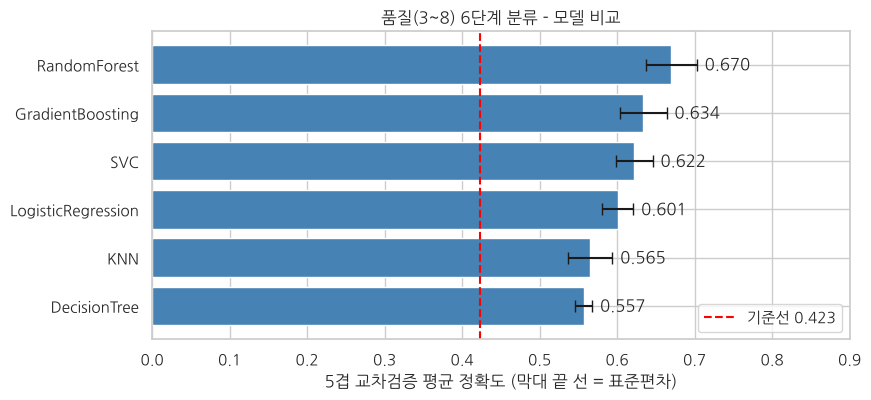

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(result6['모델'], result6['평균 정확도'], xerr=result6['표준편차'], color='steelblue', capsize=4)
ax.axvline(baseline, color='red', ls='--', label=f'기준선 {baseline:.3f}')
for i, (v, sd) in enumerate(zip(result6['평균 정확도'], result6['표준편차'])):
    ax.text(v + sd + 0.01, i, f'{v:.3f}', va='center')
ax.invert_yaxis()
ax.set_xlim(0, 0.9)
ax.set_xlabel('5겹 교차검증 평균 정확도 (막대 끝 선 = 표준편차)')
ax.set_title('품질(3~8) 6단계 분류 - 모델 비교')
ax.legend(loc='lower right')
plt.show()

* 한줄 확인 : **RandomForest가 0.670 ± 0.033으로 가장 높고**, GradientBoosting 0.634, SVC 0.622, LogisticRegression 0.601 순이다.
  * 모든 모델이 기준선(모두 품질 5로 예측, 0.423)보다 높다. 단일 DecisionTree(0.557)는 RandomForest보다 약 11%p 낮다.

### 5. GridSearchCV로 간단히 튜닝하기
 * 기본 분석처럼 테스트 점수를 보며 고르면 테스트 데이터에 맞추게 된다.
 * 올바른 순서 : ① 테스트 데이터를 먼저 떼어 두고 → ② **학습 데이터 안에서 교차검증**으로 하이퍼파라미터 선택 → ③ 마지막에 테스트 데이터로 **한 번만** 평가

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

param_grid = {
    'model__max_depth': [5, 10, None],
    'model__min_samples_leaf': [1, 3],
    'model__max_features': ['sqrt', 0.5],
}
grid = GridSearchCV(models['RandomForest'], param_grid, cv=skf, scoring='accuracy', n_jobs=2)
grid.fit(X_train, y_train)

print('최적 파라미터 :', grid.best_params_)
print('학습 데이터 교차검증 정확도 : %.3f' % grid.best_score_)
print('테스트 정확도 (한 번만 평가) : %.3f' % grid.score(X_test, y_test))

최적 파라미터 : {'model__max_depth': None, 'model__max_features': 0.5, 'model__min_samples_leaf': 1}
학습 데이터 교차검증 정확도 : 0.662
테스트 정확도 (한 번만 평가) : 0.699


In [12]:
# 조합별 교차검증 점수 (상위 5개)
cvres = pd.DataFrame(grid.cv_results_)
cols = ['param_model__max_depth', 'param_model__min_samples_leaf', 'param_model__max_features',
        'mean_test_score', 'std_test_score', 'rank_test_score']
cvres[cols].sort_values('rank_test_score').head().round(3)

,param_model__max_depth,param_model__min_samples_leaf,param_model__max_features,mean_test_score,std_test_score,rank_test_score
10,None,1,0.5,0.662,0.046,1
4,10,1,sqrt,0.658,0.054,2
8,None,1,sqrt,0.658,0.050,3
6,10,1,0.5,0.652,0.052,4
7,10,3,0.5,0.652,0.056,5


* 한줄 확인 : 12개 조합 중 `max_depth=None, max_features=0.5, min_samples_leaf=1`이 학습 데이터 교차검증 **0.662**로 가장 좋았다.
  * 상위 5개 조합의 차이는 0.010 이내이고 표준편차(약 0.05)보다 작다. → 튜닝 효과는 크지 않으며, 기본 설정도 충분히 좋은 편이다.
  * 테스트 정확도 0.699는 교차검증 점수보다 높은데, 2절에서 본 것처럼 **한 번의 분할 점수는 0.60~0.73 사이에서 흔들릴 수 있다**. 보고할 때는 교차검증 점수(0.662)를 함께 적는다.

### 6. 품질을 3등급(낮음/보통/높음)으로 묶어 분류하기
 * 품질 3, 4, 8은 개수가 매우 적어 모델이 거의 맞히지 못한다. 실제 활용에서는 "좋은 와인인가?" 정도의 구분이 더 유용할 수 있다.
 * 낮음 : 3~5 / 보통 : 6 / 높음 : 7~8

In [13]:
y3 = pd.cut(y, bins=[0, 5, 6, 10], labels=['낮음', '보통', '높음'])
print(y3.value_counts()[['낮음', '보통', '높음']])
print('기준선 (모두 가장 많은 등급으로 예측) : %.3f' % y3.value_counts(normalize=True).max())

quality
낮음    522
보통    462
높음    159
Name: count, dtype: int64
기준선 (모두 가장 많은 등급으로 예측) : 0.457


In [14]:
rows = []
for name in ['LogisticRegression', 'RandomForest', 'GradientBoosting']:
    # cross_validate : 여러 평가지표를 한 번에 계산
    r = cross_validate(models[name], X, y3, cv=skf, scoring=['accuracy', 'f1_macro'])
    rows.append({'모델': name, '정확도': r['test_accuracy'].mean(), '정확도 표준편차': r['test_accuracy'].std(),
                 'macro F1': r['test_f1_macro'].mean()})
pd.DataFrame(rows).round(3)

,모델,정확도,정확도 표준편차,macro F1
0,LogisticRegression,0.642,0.028,0.595
1,RandomForest,0.703,0.038,0.682
2,GradientBoosting,0.664,0.024,0.639


              precision    recall  f1-score   support

          낮음      0.788     0.848     0.817       105
          보통      0.707     0.707     0.707        92
          높음      0.708     0.531     0.607        32

    accuracy                          0.747       229
   macro avg      0.734     0.695     0.710       229
weighted avg      0.744     0.747     0.743       229



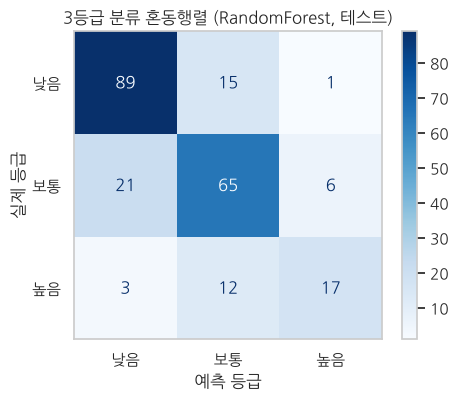

In [15]:
# 테스트 데이터로 혼동행렬 확인 (RandomForest)
y3_train, y3_test = y3.loc[X_train.index], y3.loc[X_test.index]
rf3 = models['RandomForest'].fit(X_train, y3_train)
pred3 = rf3.predict(X_test)

print(classification_report(y3_test, pred3, labels=['낮음', '보통', '높음'], digits=3))
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y3_test, pred3, labels=['낮음', '보통', '높음'], cmap='Blues', ax=ax)
ax.set_title('3등급 분류 혼동행렬 (RandomForest, 테스트)')
ax.set_xlabel('예측 등급')
ax.set_ylabel('실제 등급')
ax.grid(False)
plt.show()

* 한줄 확인 : 3등급은 낮음 522 / 보통 462 / 높음 159개, 기준선은 0.457이다.
  * 교차검증 정확도는 **RandomForest 0.703**(macro F1 0.682)로 가장 높고, GradientBoosting 0.664, LogisticRegression 0.642 순이다.
  * 테스트 데이터(229개)에서 정확도 0.747. **낮음**은 재현율 0.848로 잘 찾지만, **높음**은 재현율 0.531로 32개 중 17개만 맞히고 12개를 보통으로 예측했다. 개수가 적은 등급일수록 맞히기 어렵다.

### 7. 변수 중요도
 * `feature_importances_` : 트리가 학습하면서 각 변수로 얼마나 잘 나눴는지(불순도 감소)의 합. 빠르지만 값 종류가 많은 변수를 과대평가하는 경향이 있다.
 * `permutation importance` : **테스트 데이터**에서 한 변수의 값을 무작위로 섞었을 때 정확도가 얼마나 떨어지는지. 모델 종류와 상관없이 쓸 수 있다.
 * 6단계 품질 분류의 GridSearchCV 최적 모델(`grid.best_estimator_`)로 계산한다.

In [16]:
best = grid.best_estimator_
imp = pd.DataFrame({'변수': features,
                    'feature_importances_': best.named_steps['model'].feature_importances_})

perm = permutation_importance(best, X_test, y_test, n_repeats=10, random_state=42, n_jobs=2)
imp['permutation (정확도 감소)'] = perm.importances_mean
imp['permutation 표준편차'] = perm.importances_std
imp = imp.sort_values('permutation (정확도 감소)', ascending=False).round(4)
imp

,변수,feature_importances_,permutation (정확도 감소),permutation 표준편차
10,alcohol,0.1588,0.1341,0.0330
9,sulphates,0.1187,0.0585,0.0131
1,volatile acidity,0.1131,0.0445,0.0176
6,total sulfur dioxide,0.0972,0.0223,0.0123
5,free sulfur dioxide,0.0622,0.0183,0.0095
2,citric acid,0.0760,0.0179,0.0158
7,density,0.0804,0.0118,0.0114
0,fixed acidity,0.0735,0.0070,0.0090
3,residual sugar,0.0653,0.0066,0.0056
4,chlorides,0.0749,-0.0035,0.0055


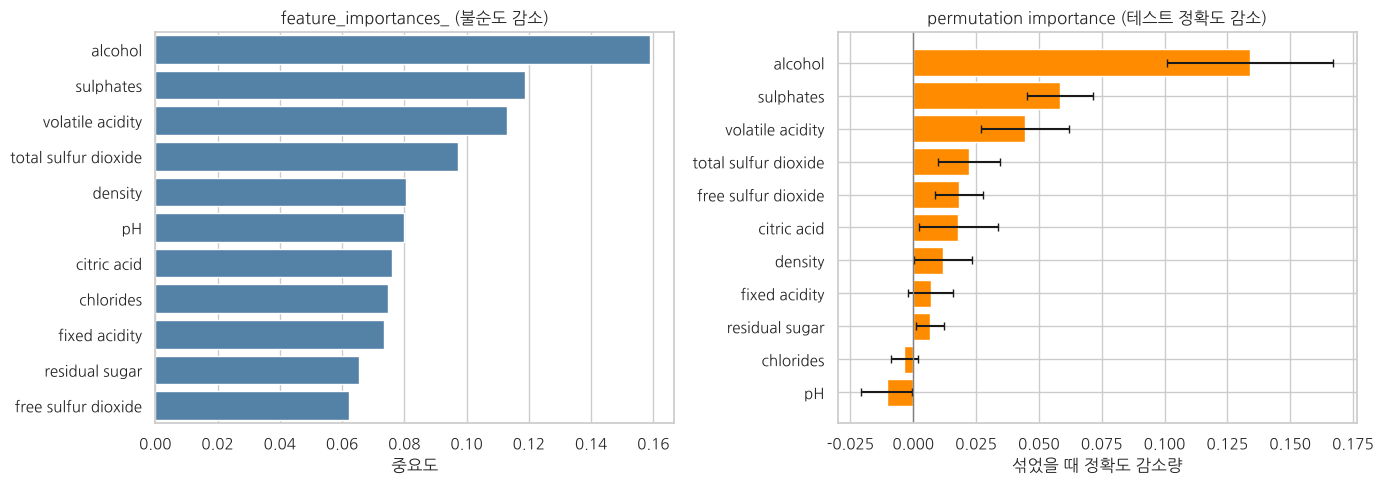

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
order = imp.sort_values('feature_importances_', ascending=False)
sns.barplot(data=order, y='변수', x='feature_importances_', color='steelblue', ax=axes[0])
axes[0].set_title('feature_importances_ (불순도 감소)')
axes[0].set_xlabel('중요도')
axes[0].set_ylabel('')

axes[1].barh(imp['변수'], imp['permutation (정확도 감소)'], xerr=imp['permutation 표준편차'],
             color='darkorange', capsize=3)
axes[1].invert_yaxis()
axes[1].axvline(0, color='gray', lw=1)
axes[1].set_title('permutation importance (테스트 정확도 감소)')
axes[1].set_xlabel('섞었을 때 정확도 감소량')
plt.tight_layout()
plt.show()

In [18]:
# 기본 분석에서 사용한 4개 변수의 permutation 순위
imp['permutation 순위'] = range(1, len(imp) + 1)
imp.set_index('변수').loc[base_sel, ['permutation (정확도 감소)', 'permutation 순위']]

,permutation (정확도 감소),permutation 순위
변수,,
fixed acidity,0.0070,8
volatile acidity,0.0445,3
citric acid,0.0179,6
residual sugar,0.0066,9


* 한줄 확인 : 두 방법 모두 **alcohol(알코올)이 1위**, sulphates(황산염), volatile acidity(휘발성 산도)가 2~3위로 같다.
  * permutation에서 alcohol을 섞으면 테스트 정확도가 **0.134** 떨어진다. 2위 sulphates(0.059)의 두 배 이상.
  * feature_importances_로는 각각 6위, 8위인 pH, chlorides가 permutation에서는 **0보다 작다**(섞어도 정확도가 떨어지지 않음) → 불순도 기반 중요도는 실제 기여보다 높게 보일 수 있다.
  * 기본 분석의 4개 변수 중 volatile acidity만 상위(3위)이고, fixed acidity(8위), residual sugar(9위)는 하위권이다. 가장 중요한 alcohol, sulphates를 빼고 있었던 것이 기본 분석 성능이 낮았던 이유다.

### 8. 정리
| 질문 | 기본 분석 | 추가 분석 결과 |
|---|---|---|
| 모델 성능을 어떻게 평가하나? | train_test_split 1회 | 분할만 바꿔도 0.598~0.729로 흔들림 → **5겹 층화 교차검증**(평균 표준편차 0.004) |
| 기본 분석 모델의 실제 성능은? | 테스트 0.612 (테스트 점수로 튜닝) | 교차검증 0.549 ± 0.035 |
| 변수를 모두 쓰면? | 4개 변수 | 11개 변수(Id 제외)로 같은 모델 0.634, RandomForest 기본 0.670 |
| 스케일링이 중요한가? | - | KNN 0.497 → Pipeline(StandardScaler+KNN) 0.565 |
| 가장 좋은 모델은? | RandomForest(depth=7, 500개) | RandomForest 0.670 > GradientBoosting 0.634 > SVC 0.622 (기준선 0.423) |
| 튜닝 효과는? | 테스트 점수 보며 수동 선택 | GridSearchCV 최적 CV 0.662, 상위 조합 간 차이 0.010 이내 |
| 3등급으로 묶으면? | - | RandomForest CV 정확도 0.703, macro F1 0.682 (높음 등급 재현율 0.531) |
| 중요한 변수는? | - | **alcohol** > sulphates > volatile acidity (두 방법 모두 상위 3개 동일) |

#### 배운 점
 * **split 1회 점수는 운에 따라 흔들린다.** 모델 비교·튜닝은 층화 교차검증(StratifiedKFold) 평균과 표준편차로 한다.
 * 스케일링 같은 전처리는 **Pipeline**에 넣어 교차검증의 각 fold 안에서만 학습시킨다(데이터 누수 방지, 코드도 간단).
 * 하이퍼파라미터는 테스트 데이터가 아니라 **학습 데이터 안의 교차검증(GridSearchCV)**으로 고르고, 테스트는 마지막에 한 번만 본다.
 * `Id`처럼 의미 없는 컬럼은 반드시 빼고, 변수 중요도는 **두 가지 방법을 함께** 확인한다.

#### 다음에 해 볼 분석
 * 공통 모델링 시리즈 ② : 클래스 불균형 다루기(class_weight, 평가지표 macro F1/ROC-AUC)
 * 품질을 숫자로 보고 **회귀 모델**로 예측한 뒤 반올림하여 분류 결과와 비교하기